In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Використовується пристрій: {device}")

transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False, num_workers=2)

print("Дані успішно завантажено та підготовлено.")

Використовується пристрій: cpu


100%|██████████| 170M/170M [00:31<00:00, 5.37MB/s] 


Дані успішно завантажено та підготовлено.


In [3]:
class PlantCNN(nn.Module):
    def __init__(self):
        super(PlantCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool = nn.MaxPool2d(2)
        
        self.flatten = nn.Flatten()
        
        self.fc1 = nn.Linear(32 * 16 * 16, 128)
        self.relu2 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.conv1(x)
        x = self.relu1(x)
        x = self.pool(x)
        
        x = self.flatten(x)
        
        x = self.fc1(x)
        x = self.relu2(x)
        x = self.fc2(x)
        return x

model = PlantCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Модель створено:")
print(model)

Модель створено:
PlantCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=8192, out_features=128, bias=True)
  (relu2): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


Початок навчання...
Епоха [1/5], Втрати (Loss): 1.3727
Епоха [2/5], Втрати (Loss): 1.0671
Епоха [3/5], Втрати (Loss): 0.9276
Епоха [4/5], Втрати (Loss): 0.8202
Епоха [5/5], Втрати (Loss): 0.7280


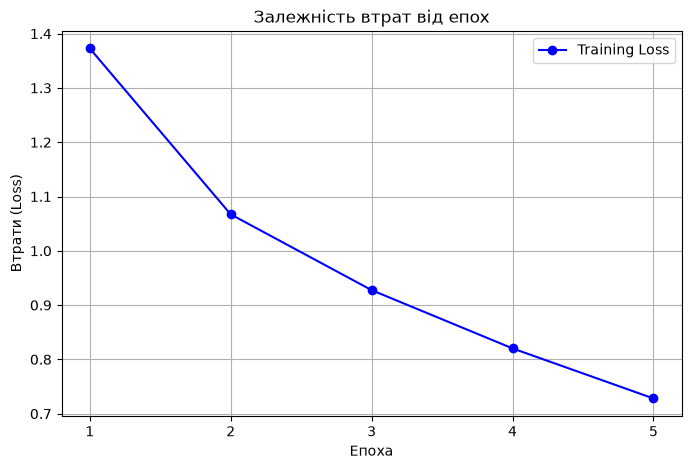

Модель успішно збережено у файл: plant_cnn.pth


In [4]:
epochs = 5
epoch_losses = []

print("Початок навчання...")
for epoch in range(epochs):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data[0].to(device), data[1].to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    avg_loss = running_loss / len(trainloader)
    epoch_losses.append(avg_loss)
    print(f"Епоха [{epoch + 1}/{epochs}], Втрати (Loss): {avg_loss:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), epoch_losses, marker='o', color='b', label='Training Loss')
plt.title('Залежність втрат від епох')
plt.xlabel('Епоха')
plt.ylabel('Втрати (Loss)')
plt.xticks(range(1, epochs + 1))
plt.grid(True)
plt.legend()
plt.show()

model_path = 'plant_cnn.pth'
torch.save(model.state_dict(), model_path)
print(f"Модель успішно збережено у файл: {model_path}")

In [5]:
correct = 0
total = 0
test_loss = 0.0

model.eval() 
with torch.no_grad(): 
    for data in testloader:
        inputs, labels = data[0].to(device), data[1].to(device)
        outputs = model(inputs)

        loss = criterion(outputs, labels)
        test_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
avg_test_loss = test_loss / len(testloader)

print(f"{'Метрика':<10} {'Значення'}")
print("-" * 20)
print(f"{'Accuracy':<10} {accuracy:.2f}%")
print(f"{'Loss':<10} {avg_test_loss:.4f}")

Метрика    Значення
--------------------
Accuracy   66.18%
Loss       0.9778
